In [ ]:
!pip install -q pandas numpy geopandas shapely folium scikit-learn joblib requests geopy

In [ ]:
import os
import re
import json
import joblib
import requests
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from shapely.geometry import (
    Point,
    LineString,
    MultiLineString
)

from geopy.geocoders import Nominatim

from IPython.display import display

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

PROCESSED_PATH = BASE_PATH + "/datasets/processed"

GIS_PATH = PROCESSED_PATH + "/gis"

VALIDATED_PATH = PROCESSED_PATH + "/validated"

ZOMATO_PATH = (
    BASE_PATH +
    "/datasets/raw/zomato/zomato_cleaned_dataset.csv"
)

FORUM_MODEL_PATH = BASE_PATH + "/models/forum_nlp"

TRAVEL_MODEL_PATH = BASE_PATH + "/models/travel_time"

OUTPUT_PATH = PROCESSED_PATH + "/route_intelligence"

REPORT_PATH = BASE_PATH + "/reports/route_intelligence"

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Project paths configured!")

Project paths configured!


In [ ]:
forum_model = joblib.load(
    FORUM_MODEL_PATH + "/forum_category_model.pkl"
)

forum_vectorizer = joblib.load(
    FORUM_MODEL_PATH + "/forum_tfidf_vectorizer.pkl"
)

print("Forum NLP model loaded!")

Forum NLP model loaded!


In [ ]:
travel_model = joblib.load(
    TRAVEL_MODEL_PATH + "/travel_time_prediction_model.pkl"
)

print("Travel-time prediction model loaded!")

Travel-time prediction model loaded!


In [ ]:
forum_posts = pd.read_csv(
    VALIDATED_PATH + "/forum_posts_validated.csv"
)

forum_comments = pd.read_csv(
    VALIDATED_PATH + "/forum_comments_validated.csv"
)

print("Forum posts:", forum_posts.shape)
print("Forum comments:", forum_comments.shape)

display(forum_posts.head())

Forum posts: (1000, 22)
Forum comments: (1949, 8)


,post_id,user_id,title,text,category,subcategory,severity,location_name,latitude,longitude,...,expires_at,sentiment,upvotes,comment_count,status,source_type,verification_status,is_synthetic,template_id,text_length
0,P00001,U012,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,0,Medium,Bhubaneswar road segment,20.153729,85.720593,...,2026-12-09 15:23:13.247992105+00:00,Negative,37,1,Active,synthetic,synthetic_unverified,True,Road Hazard_01,71
1,P00002,U026,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,0,Low,Bhubaneswar road segment,20.225751,85.813249,...,2026-11-01 17:13:43.053302191+00:00,Positive,45,1,Expired,synthetic,synthetic_unverified,True,Route Tip_01,75
2,P00003,U090,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,1,Low,Bhubaneswar road segment,20.186956,85.630708,...,2026-11-19 12:12:59.198244989+00:00,Positive,27,3,Active,synthetic,synthetic_unverified,True,Route Tip_02,84
3,P00004,U013,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,2,Medium,Bhubaneswar road segment,20.271767,85.794065,...,2026-11-16 15:35:28.630972967+00:00,Negative,22,3,Active,synthetic,synthetic_unverified,True,Safety Concern_03,88
4,P00005,U011,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,2,Medium,Bhubaneswar road segment,20.236510,85.812059,...,2026-10-21 15:09:07.386742449+00:00,Negative,35,2,Expired,synthetic,synthetic_unverified,True,Safety Concern_03,88


In [ ]:
forum_posts.columns = (
    forum_posts.columns
    .str.strip()
    .str.lower()
)

forum_comments.columns = (
    forum_comments.columns
    .str.strip()
    .str.lower()
)

for col in ["latitude", "longitude"]:
    if col in forum_posts.columns:
        forum_posts[col] = pd.to_numeric(
            forum_posts[col],
            errors="coerce"
        )

for col in ["created_at", "observed_at", "expires_at"]:
    if col in forum_posts.columns:
        forum_posts[col] = pd.to_datetime(
            forum_posts[col],
            errors="coerce",
            utc=True
        )

print("Forum data prepared!")

Forum data prepared!


In [ ]:
roads = gpd.read_file(
    GIS_PATH + "/roads_processed.geojson"
)

print("Roads:", len(roads))

Roads: 2574


In [ ]:
def load_optional_layer(filename):

    path = GIS_PATH + "/" + filename

    if os.path.exists(path):
        return gpd.read_file(path)

    print("Optional layer not found:", filename)
    return None


flyovers = load_optional_layer(
    "flyovers_processed.geojson"
)

junctions = load_optional_layer(
    "traffic_junctions_processed.geojson"
)

poi = load_optional_layer(
    "poi_processed.geojson"
)

In [ ]:


from geopy.geocoders import Nominatim
from geopy.exc import GeocoderTimedOut, GeocoderUnavailable
import time

geolocator = Nominatim(
    user_agent="smart_ride_intelligence_team_project_2026"
)

def get_coordinates(location_name):

    search_queries = [
        location_name,
        location_name + ", Bhubaneswar, India",
        location_name + ", Odisha, India"
    ]

    for query in search_queries:

        try:
            print("Searching:", query)

            location = geolocator.geocode(
                query,
                timeout=20,
                country_codes="in"
            )

            if location is not None:

                print("Location found!")

                return {
                    "latitude": location.latitude,
                    "longitude": location.longitude,
                    "address": location.address
                }

            time.sleep(1.2)

        except (GeocoderTimedOut, GeocoderUnavailable) as e:

            print("Geocoding service error:", e)
            time.sleep(3)

        except Exception as e:

            print("Error:", e)
            time.sleep(2)

    print("Location not found:", location_name)

    return None


In [ ]:

SOURCE_LOCATION = "KIIT University"

DESTINATION_LOCATION = "Bhubaneswar Railway Station"


In [ ]:


source = get_coordinates(SOURCE_LOCATION)

destination = get_coordinates(DESTINATION_LOCATION)

if source is None:
    raise ValueError("Source location could not be identified.")

if destination is None:
    raise ValueError("Destination location could not be identified.")

print("\nSOURCE")
print(source)

print("\nDESTINATION")
print(destination)


Searching: KIIT University
Location found!
Searching: Bhubaneswar Railway Station
Location found!

SOURCE
{'latitude': 20.3530675, 'longitude': 85.8201467, 'address': 'KIIT Campus 6 (Main Campus), KIIT Road, North Zone, Bhubaneswar Municipal Corporation, Bhubaneswar (M.Corp.), Khordha, Odisha, 751024, India'}

DESTINATION
{'latitude': 20.2667774, 'longitude': 85.8435592, 'address': 'Bhubaneswar, Lane number 1, Budheswari Colony, Ward 42, South East Zone, Bhubaneswar Municipal Corporation, Bhubaneswar (M.Corp.), Khordha, Odisha, 751006, India'}


In [ ]:
def get_route(source, destination):

    source_lon = source["longitude"]
    source_lat = source["latitude"]

    destination_lon = destination["longitude"]
    destination_lat = destination["latitude"]

    url = (
        "https://router.project-osrm.org/route/v1/driving/"
        f"{source_lon},{source_lat};"
        f"{destination_lon},{destination_lat}"
    )

    params = {
        "overview": "full",
        "geometries": "geojson",
        "steps": "true"
    }

    response = requests.get(
        url,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()

    if data.get("code") != "Ok" or not data.get("routes"):
        raise ValueError("No route found by OSRM.")

    route = data["routes"][0]

    return {
        "geometry": route["geometry"],
        "distance_km": route["distance"] / 1000,
        "duration_min": route["duration"] / 60,
        "steps": route.get("legs", [{}])[0].get("steps", [])
    }

In [ ]:
route_data = get_route(
    source,
    destination
)

route_distance = route_data["distance_km"]

osrm_duration = route_data["duration_min"]

route_coordinates = route_data["geometry"]["coordinates"]

route_line = LineString(route_coordinates)

print("Route Distance:", round(route_distance, 2), "km")

print(
    "OSRM Estimated Duration:",
    round(osrm_duration, 2),
    "minutes"
)

Route Distance: 11.98 km
OSRM Estimated Duration: 12.97 minutes


In [ ]:
route_steps = []

for step in route_data["steps"]:

    route_steps.append({
        "Road": step.get("name", "Unnamed road"),
        "Distance_km": round(
            step.get("distance", 0) / 1000, 2
        ),
        "Duration_min": round(
            step.get("duration", 0) / 60, 2
        ),
        "Instruction_Type": step.get(
            "maneuver", {}
        ).get("type", "")
    })

route_steps_df = pd.DataFrame(route_steps)

display(route_steps_df.head(20))

route_steps_df.to_csv(
    OUTPUT_PATH + "/route_steps.csv",
    index=False
)

,Road,Distance_km,Duration_min,Instruction_Type
0,KIIT Road,0.67,0.73,depart
1,Nandankanan Road,6.56,6.11,end of road
2,Bidyut Marg,2.25,2.16,turn
3,Gopabandhu Marg,0.88,0.96,turn
4,Sachivalaya Marg,0.11,0.29,end of road
5,Mahatma Gandhi Marg,0.91,1.35,turn
6,Jan Path,0.25,0.46,fork
7,,0.26,0.70,turn
8,,0.09,0.22,end of road
9,,0.00,0.00,arrive


In [ ]:
route_gdf = gpd.GeoDataFrame(
    {"route_id": [1]},
    geometry=[route_line],
    crs="EPSG:4326"
)

print(route_gdf)

   route_id                                           geometry
0         1  LINESTRING (85.82018 20.35366, 85.82038 20.353...


In [ ]:
BUFFER_DISTANCE = 500  # metres

route_metric = route_gdf.to_crs(epsg=32645)

route_buffer = route_metric.copy()

route_buffer["geometry"] = (
    route_buffer.geometry.buffer(BUFFER_DISTANCE)
)

print(
    "Route buffer created:",
    BUFFER_DISTANCE,
    "metres"
)

Route buffer created: 500 metres


In [ ]:
forum_geo = forum_posts.dropna(
    subset=["latitude", "longitude"]
).copy()

forum_geo = forum_geo[
    forum_geo["latitude"].between(-90, 90) &
    forum_geo["longitude"].between(-180, 180)
].copy()

forum_gdf = gpd.GeoDataFrame(
    forum_geo,
    geometry=gpd.points_from_xy(
        forum_geo["longitude"],
        forum_geo["latitude"]
    ),
    crs="EPSG:4326"
)

forum_metric = forum_gdf.to_crs(epsg=32645)

print("Geolocated forum posts:", len(forum_metric))

Geolocated forum posts: 1000


In [ ]:
buffer_geometry = route_buffer.geometry.iloc[0]

nearby_posts = forum_metric[
    forum_metric.geometry.within(buffer_geometry)
].copy()

print("Total forum posts:", len(forum_metric))

print("Nearby forum posts:", len(nearby_posts))

display(nearby_posts.head())

Total forum posts: 1000
Nearby forum posts: 43


,post_id,user_id,title,text,category,subcategory,severity,location_name,latitude,longitude,...,sentiment,upvotes,comment_count,status,source_type,verification_status,is_synthetic,template_id,text_length,geometry
42,P00043,U029,Temporary road diversion,A temporary traffic diversion is associated wi...,Construction,2,Low,Bhubaneswar road segment,20.272799,85.833513,...,Neutral,12,1,Expired,synthetic,synthetic_unverified,True,Construction_03,88,POINT (378184.548 2242099.426)
120,P00121,U065,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,1,Low,Bhubaneswar road segment,20.282970,85.826948,...,Positive,17,1,Expired,synthetic,synthetic_unverified,True,Route Tip_02,84,POINT (377506.793 2243229.997)
147,P00148,U057,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,0,High,Bhubaneswar road segment,20.272096,85.842499,...,Negative,42,1,Active,synthetic,synthetic_unverified,True,Road Hazard_01,71,POINT (379122.415 2242014.954)
170,P00171,U099,Slow-moving traffic,Traffic movement is slow near Bhubaneswar road...,Traffic,2,Low,Bhubaneswar road segment,20.268094,85.840862,...,Negative,39,2,Expired,synthetic,synthetic_unverified,True,Traffic_03,85,POINT (378948.415 2241573.283)
217,P00218,U098,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,0,Low,Bhubaneswar road segment,20.280816,85.826669,...,Positive,35,3,Expired,synthetic,synthetic_unverified,True,Route Tip_01,75,POINT (377475.994 2242991.854)


In [ ]:
def clean_forum_text(text):

    text = str(text).lower()

    text = re.sub(
        r"http\S+|www\S+",
        "",
        text
    )

    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [ ]:
if len(nearby_posts) > 0:

    if "combined_text" in nearby_posts.columns:

        text_column = "combined_text"

    else:

        title_text = nearby_posts.get(
            "title",
            pd.Series("", index=nearby_posts.index)
        ).fillna("")

        body_text = nearby_posts.get(
            "text",
            pd.Series("", index=nearby_posts.index)
        ).fillna("")

        nearby_posts["combined_text"] = (
            title_text.astype(str) + " " +
            body_text.astype(str)
        )

        text_column = "combined_text"

    cleaned_texts = (
        nearby_posts[text_column]
        .fillna("")
        .apply(clean_forum_text)
    )

    text_vectors = forum_vectorizer.transform(
        cleaned_texts
    )

    nearby_posts["predicted_category"] = (
        forum_model.predict(text_vectors)
    )

    if hasattr(forum_model, "predict_proba"):

        probabilities = forum_model.predict_proba(
            text_vectors
        )

        nearby_posts["prediction_confidence"] = (
            probabilities.max(axis=1)
        )

else:

    nearby_posts["predicted_category"] = pd.Series(
        dtype="object"
    )

print("Forum classification completed!")

display(
    nearby_posts[
        [
            "title",
            "predicted_category"
        ]
    ].head(10)
)

Forum classification completed!


,title,predicted_category
42,Temporary road diversion,Construction
120,Suggested route for riders,Route Tip
147,Potholes reported near Bhubaneswar road segment,Road Hazard
170,Slow-moving traffic,Normal
217,Alternative route suggestion,Route Tip
252,Poor street lighting,Safety Concern
296,Route information,Route Tip
318,Limited pedestrian visibility,Safety Concern
346,Accident-related traffic delay,Accident
370,Poor visibility at night,Safety Concern


In [ ]:
if len(nearby_posts) > 0:

    category_summary = (
        nearby_posts["predicted_category"]
        .value_counts()
        .reset_index()
    )

    category_summary.columns = [
        "Category",
        "Number_of_Reports"
    ]

else:

    category_summary = pd.DataFrame(
        columns=["Category", "Number_of_Reports"]
    )

display(category_summary)

,Category,Number_of_Reports
0,Traffic,8
1,Accident,8
2,Normal,6
3,Safety Concern,6
4,Route Tip,5
5,Waterlogging,5
6,Road Hazard,4
7,Construction,1


In [ ]:
if len(nearby_posts) > 0 and "severity" in nearby_posts.columns:

    severity_summary = (
        nearby_posts["severity"]
        .fillna("Not Specified")
        .value_counts()
        .reset_index()
    )

    severity_summary.columns = [
        "Severity",
        "Number_of_Reports"
    ]

else:

    severity_summary = pd.DataFrame(
        columns=["Severity", "Number_of_Reports"]
    )

display(severity_summary)

,Severity,Number_of_Reports
0,High,16
1,Medium,14
2,Low,13


In [ ]:
if len(nearby_posts) > 0 and "sentiment" in nearby_posts.columns:

    sentiment_summary = (
        nearby_posts["sentiment"]
        .fillna("Not Specified")
        .value_counts()
        .reset_index()
    )

    sentiment_summary.columns = [
        "Sentiment",
        "Number_of_Reports"
    ]

else:

    sentiment_summary = pd.DataFrame(
        columns=["Sentiment", "Number_of_Reports"]
    )

display(sentiment_summary)

,Sentiment,Number_of_Reports
0,Negative,33
1,Positive,9
2,Neutral,1


In [ ]:
if len(nearby_posts) > 0 and "post_id" in nearby_posts.columns:

    nearby_post_ids = nearby_posts["post_id"].astype(str)

    comments_copy = forum_comments.copy()

    comments_copy["post_id"] = (
        comments_copy["post_id"].astype(str)
    )

    nearby_comments = comments_copy[
        comments_copy["post_id"].isin(nearby_post_ids)
    ].copy()

else:

    nearby_comments = pd.DataFrame()

print("Comments related to nearby posts:", len(nearby_comments))

display(nearby_comments.head())

Comments related to nearby posts: 87


,comment_id,post_id,user_id,comment_text,created_at,sentiment,source_type,is_synthetic
75,C000076,P00043,U035,Construction-related delays may occur.,2026-10-17T21:13:56.896688801+05:30,Neutral,synthetic,True
231,C000232,P00121,U064,Other riders may find this useful.,2026-10-14T23:04:04.889703290+05:30,Positive,synthetic,True
281,C000282,P00148,U036,This may require attention from the concerned ...,2026-10-23T19:44:25.760891433+05:30,Negative,synthetic,True
326,C000327,P00171,U035,Consider checking the route before travelling.,2026-11-07T14:04:34.186270161+05:30,Negative,synthetic,True
327,C000328,P00171,U001,An alternative route may be worth checking.,2026-11-07T13:10:34.186270161+05:30,Negative,synthetic,True


In [ ]:
def generate_route_summary(
    nearby_posts,
    category_summary,
    severity_summary
):

    if len(nearby_posts) == 0:

        return (
            "No forum reports were found within "
            f"{BUFFER_DISTANCE} metres of this route. "
            "This does not guarantee that the route is clear."
        )

    total_reports = len(nearby_posts)

    summary = [
        f"{total_reports} forum report(s) were found "
        f"within {BUFFER_DISTANCE} metres of the selected route."
    ]

    if not category_summary.empty:

        top_categories = category_summary.head(4)

        category_text = ", ".join(
            [
                f"{row['Category']} ({row['Number_of_Reports']})"
                for _, row in top_categories.iterrows()
            ]
        )

        summary.append(
            "Most common report categories: " + category_text + "."
        )

    if not severity_summary.empty:

        severity_text = ", ".join(
            [
                f"{row['Severity']} ({row['Number_of_Reports']})"
                for _, row in severity_summary.iterrows()
            ]
        )

        summary.append(
            "Reported severity distribution: " +
            severity_text + "."
        )

    return " ".join(summary)


route_summary = generate_route_summary(
    nearby_posts,
    category_summary,
    severity_summary
)

print(route_summary)

43 forum report(s) were found within 500 metres of the selected route. Most common report categories: Traffic (8), Accident (8), Normal (6), Safety Concern (6). Reported severity distribution: High (16), Medium (14), Low (13).


In [ ]:
display_columns = [
    col for col in [
        "title",
        "text",
        "predicted_category",
        "severity",
        "sentiment",
        "location_name",
        "created_at",
        "upvotes"
    ]
    if col in nearby_posts.columns
]

display(
    nearby_posts[display_columns].head(30)
)

,title,text,predicted_category,severity,sentiment,location_name,created_at,upvotes
42,Temporary road diversion,A temporary traffic diversion is associated wi...,Construction,Low,Neutral,Bhubaneswar road segment,2026-10-17 15:31:56.896688801+00:00,12
120,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,Low,Positive,Bhubaneswar road segment,2026-10-14 16:19:04.889703290+00:00,17
147,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,High,Negative,Bhubaneswar road segment,2026-10-23 13:38:25.760891433+00:00,42
170,Slow-moving traffic,Traffic movement is slow near Bhubaneswar road...,Normal,Low,Negative,Bhubaneswar road segment,2026-11-07 07:12:34.186270161+00:00,39
217,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,Low,Positive,Bhubaneswar road segment,2026-11-01 03:51:50.209688196+00:00,35
252,Poor street lighting,Street lighting is described as inadequate nea...,Safety Concern,Low,Negative,Bhubaneswar road segment,2026-11-08 21:34:05.494928883+00:00,48
296,Route information,A connecting road near Bhubaneswar road segmen...,Route Tip,Low,Positive,Bhubaneswar road segment,2026-10-24 00:36:52.942350381+00:00,4
318,Limited pedestrian visibility,Pedestrian visibility is described as poor nea...,Safety Concern,Medium,Negative,Bhubaneswar road segment,2026-10-19 09:34:30.507909187+00:00,22
346,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,High,Negative,Bhubaneswar road segment,2026-11-09 06:10:54.699283690+00:00,2
370,Poor visibility at night,Visibility may be reduced near Bhubaneswar roa...,Safety Concern,Medium,Negative,Bhubaneswar road segment,2026-11-04 17:46:34.301575259+00:00,14


In [ ]:
nearby_posts_wgs84 = nearby_posts.to_crs(epsg=4326)

nearby_posts_wgs84.drop(
    columns=["geometry"],
    errors="ignore"
).to_csv(
    OUTPUT_PATH + "/nearby_forum_posts.csv",
    index=False
)

nearby_comments.to_csv(
    OUTPUT_PATH + "/nearby_forum_comments.csv",
    index=False
)

category_summary.to_csv(
    OUTPUT_PATH + "/route_category_summary.csv",
    index=False
)

severity_summary.to_csv(
    OUTPUT_PATH + "/route_severity_summary.csv",
    index=False
)

sentiment_summary.to_csv(
    OUTPUT_PATH + "/route_sentiment_summary.csv",
    index=False
)

with open(
    OUTPUT_PATH + "/route_forum_summary.txt",
    "w"
) as f:

    f.write(route_summary)

print("Route forum reports saved!")

Route forum reports saved!


In [ ]:
zomato = pd.read_csv(ZOMATO_PATH)

zomato.columns = (
    zomato.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Zomato data loaded:", zomato.shape)
print(zomato.columns.tolist())

Zomato data loaded: (38964, 22)
['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_orderd', 'time_order_picked', 'weather_conditions', 'road_traffic_density', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'time_taken_min', 'distance_km', 'delivery_speed']


In [ ]:
numeric_columns = [
    "delivery_person_age",
    "delivery_person_ratings",
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude",
    "vehicle_condition",
    "multiple_deliveries",
    "time_taken_min",
    "distance_km"
]

for col in numeric_columns:

    if col in zomato.columns:

        zomato[col] = pd.to_numeric(
            zomato[col],
            errors="coerce"
        )


def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) *
        np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    return R * 2 * np.arcsin(np.sqrt(a))


if all(
    col in zomato.columns
    for col in [
        "restaurant_latitude",
        "restaurant_longitude",
        "delivery_location_latitude",
        "delivery_location_longitude"
    ]
):

    zomato["geo_distance_km"] = haversine_distance(
        zomato["restaurant_latitude"],
        zomato["restaurant_longitude"],
        zomato["delivery_location_latitude"],
        zomato["delivery_location_longitude"]
    )


if "time_orderd" in zomato.columns:

    zomato["order_hour"] = pd.to_datetime(
        zomato["time_orderd"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour

elif "time_ordered" in zomato.columns:

    zomato["order_hour"] = pd.to_datetime(
        zomato["time_ordered"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour

else:

    zomato["order_hour"] = np.nan


if "order_date" in zomato.columns:

    zomato["order_date"] = pd.to_datetime(
        zomato["order_date"],
        errors="coerce",
        dayfirst=True
    )

    zomato["day_of_week"] = (
        zomato["order_date"].dt.dayofweek
    )

else:

    zomato["day_of_week"] = np.nan

print("Feature engineering completed!")

Feature engineering completed!


In [ ]:
expected_features = list(
    travel_model.feature_names_in_
)

print("Model expects these features:")
print(expected_features)

Model expects these features:
['distance_km', 'geo_distance_km', 'delivery_person_age', 'delivery_person_ratings', 'vehicle_condition', 'multiple_deliveries', 'weather_conditions', 'road_traffic_density', 'type_of_order', 'type_of_vehicle', 'city', 'festival', 'order_hour', 'day_of_week']


In [ ]:
sample_input = {}

for col in expected_features:

    if col not in zomato.columns:

        raise ValueError(
            f"Required model feature missing from Zomato data: {col}"
        )

    series = zomato[col]

    if pd.api.types.is_numeric_dtype(series):

        sample_input[col] = series.median()

    else:

        modes = series.dropna().mode()

        if len(modes) > 0:
            sample_input[col] = modes.iloc[0]
        else:
            sample_input[col] = np.nan


travel_input = pd.DataFrame(
    [sample_input],
    columns=expected_features
)

display(travel_input)

,distance_km,geo_distance_km,delivery_person_age,delivery_person_ratings,vehicle_condition,multiple_deliveries,weather_conditions,road_traffic_density,type_of_order,type_of_vehicle,city,festival,order_hour,day_of_week
0,9.219906,9.219906,30.0,4.7,1.0,1.0,Fog,Low,Snack,motorcycle,Metropolitian,No,19.0,3.0


In [ ]:
# The OSRM route distance is the road-network distance.
# The direct distance between the endpoints is the geographic distance.

direct_distance = haversine_distance(
    source["latitude"],
    source["longitude"],
    destination["latitude"],
    destination["longitude"]
)

if "distance_km" in travel_input.columns:

    travel_input.loc[0, "distance_km"] = route_distance

if "geo_distance_km" in travel_input.columns:

    travel_input.loc[0, "geo_distance_km"] = direct_distance

print("Route distance:", round(route_distance, 2), "km")

print(
    "Direct geographic distance:",
    round(float(direct_distance), 2),
    "km"
)

Route distance: 11.98 km
Direct geographic distance: 9.9 km


In [ ]:
predicted_delivery_time = travel_model.predict(
    travel_input
)[0]

print(
    "Model estimated delivery time:",
    round(predicted_delivery_time, 2),
    "minutes"
)

print(
    "OSRM estimated driving duration:",
    round(osrm_duration, 2),
    "minutes"
)

Model estimated delivery time: 23.59 minutes
OSRM estimated driving duration: 12.97 minutes


In [ ]:
route_metrics = pd.DataFrame({
    "Metric": [
        "Route Distance",
        "OSRM Driving Duration",
        "Model Predicted Delivery Time",
        "Nearby Forum Reports",
        "Nearby Forum Comments"
    ],

    "Value": [
        round(route_distance, 2),
        round(osrm_duration, 2),
        round(predicted_delivery_time, 2),
        len(nearby_posts),
        len(nearby_comments)
    ],

    "Unit": [
        "km",
        "minutes",
        "minutes",
        "reports",
        "comments"
    ]
})

display(route_metrics)

route_metrics.to_csv(
    OUTPUT_PATH + "/route_metrics.csv",
    index=False
)

,Metric,Value,Unit
0,Route Distance,11.98,km
1,OSRM Driving Duration,12.97,minutes
2,Model Predicted Delivery Time,23.59,minutes
3,Nearby Forum Reports,43.00,reports
4,Nearby Forum Comments,87.00,comments


In [ ]:
route_map = folium.Map(
    location=[
        source["latitude"],
        source["longitude"]
    ],
    zoom_start=12,
    tiles="CartoDB positron"
)

In [ ]:
folium.Marker(
    location=[
        source["latitude"],
        source["longitude"]
    ],
    popup="Source: " + SOURCE_LOCATION,
    tooltip="Source",
    icon=folium.Icon(color="green", icon="play")
).add_to(route_map)


folium.Marker(
    location=[
        destination["latitude"],
        destination["longitude"]
    ],
    popup="Destination: " + DESTINATION_LOCATION,
    tooltip="Destination",
    icon=folium.Icon(color="red", icon="flag")
).add_to(route_map)

In [ ]:
route_latlon = [
    [lat, lon]
    for lon, lat in route_coordinates
]

folium.PolyLine(
    locations=route_latlon,
    color="blue",
    weight=5,
    opacity=0.85,
    tooltip="Selected Route"
).add_to(route_map)

In [ ]:
category_colors = {
    "Traffic": "orange",
    "Accident": "red",
    "Road Hazard": "darkred",
    "Construction": "purple",
    "Waterlogging": "blue",
    "Safety Concern": "darkpurple",
    "Road Quality": "cadetblue",
    "Route Suggestions": "green",
    "Travel Tips": "lightgreen",
    "General Experience": "gray",
    "Normal": "lightblue"
}

In [ ]:
for _, row in nearby_posts_wgs84.iterrows():

    category = row.get(
        "predicted_category",
        "Unknown"
    )

    color = category_colors.get(
        category,
        "gray"
    )

    title = str(row.get("title", "Forum Report"))

    text = str(row.get("text", ""))

    location_name = str(
        row.get("location_name", "Unknown location")
    )

    popup_text = (
        f"<b>{title}</b><br>"
        f"Category: {category}<br>"
        f"Location: {location_name}<br>"
        f"{text[:250]}"
    )

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        radius=6,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        popup=folium.Popup(
            popup_text,
            max_width=300
        ),
        tooltip=category
    ).add_to(route_map)

In [ ]:
folium.GeoJson(
    data=roads.to_json(),
    name="Bhubaneswar Road Network",
    style_function=lambda feature: {
        "color": "gray",
        "weight": 1,
        "opacity": 0.5
    }
).add_to(route_map)

In [ ]:
if flyovers is not None and len(flyovers) > 0:

    folium.GeoJson(
        data=flyovers.to_json(),
        name="Flyovers",
        style_function=lambda feature: {
            "color": "purple",
            "weight": 3
        }
    ).add_to(route_map)

In [ ]:
if junctions is not None and len(junctions) > 0:

    folium.GeoJson(
        data=junctions.to_json(),
        name="Traffic Junctions",
        marker=folium.CircleMarker(
            radius=4,
            color="red",
            fill=True
        )
    ).add_to(route_map)

In [ ]:
if poi is not None and len(poi) > 0:

    folium.GeoJson(
        data=poi.to_json(),
        name="Points of Interest",
        marker=folium.CircleMarker(
            radius=4,
            color="orange",
            fill=True
        )
    ).add_to(route_map)

In [ ]:
route_info = f"""
<b>Smart Ride Intelligence</b><br>
Source: {SOURCE_LOCATION}<br>
Destination: {DESTINATION_LOCATION}<br>
Distance: {route_distance:.2f} km<br>
OSRM Duration: {osrm_duration:.2f} minutes<br>
Predicted Delivery Time: {predicted_delivery_time:.2f} minutes<br>
Nearby Forum Reports: {len(nearby_posts)}
"""

folium.Marker(
    location=[
        source["latitude"],
        source["longitude"]
    ],
    icon=folium.DivIcon(
        html="""
        <div style="
            background:white;
            border:1px solid #333;
            padding:8px;
            width:230px;
            font-size:11px;
            border-radius:5px;">
            """ + route_info + """
        </div>
        """
    )
).add_to(route_map)

folium.LayerControl(
    collapsed=False
).add_to(route_map)

route_map.fit_bounds(route_latlon)

route_map

In [ ]:
MAP_PATH = OUTPUT_PATH + "/smart_ride_route_map.html"

route_map.save(MAP_PATH)

print("Interactive route map saved!")
print(MAP_PATH)

Interactive route map saved!
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/route_intelligence/smart_ride_route_map.html


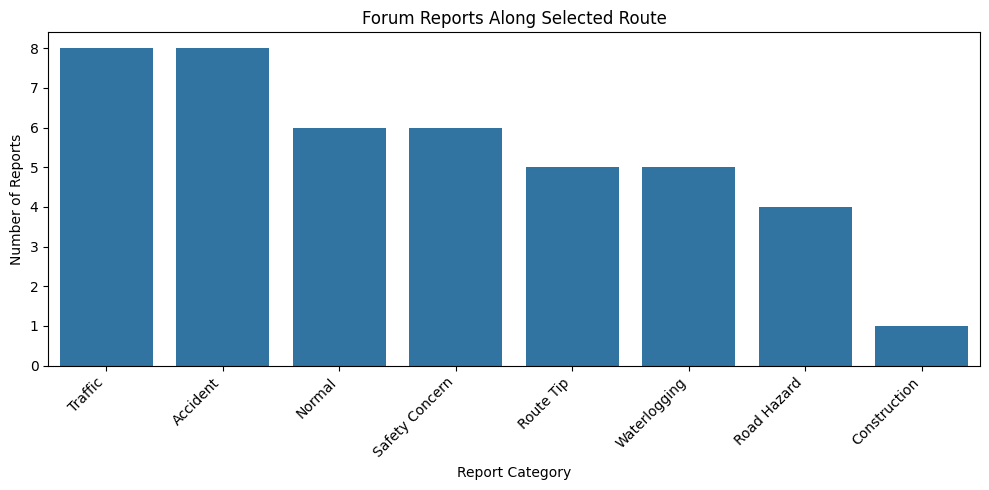

In [ ]:
if not category_summary.empty:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=category_summary,
        x="Category",
        y="Number_of_Reports"
    )

    plt.title("Forum Reports Along Selected Route")
    plt.xlabel("Report Category")
    plt.ylabel("Number of Reports")

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    plt.savefig(
        REPORT_PATH + "/route_forum_categories.png",
        dpi=300
    )

    plt.show()

else:

    print("No forum reports available for visualization.")

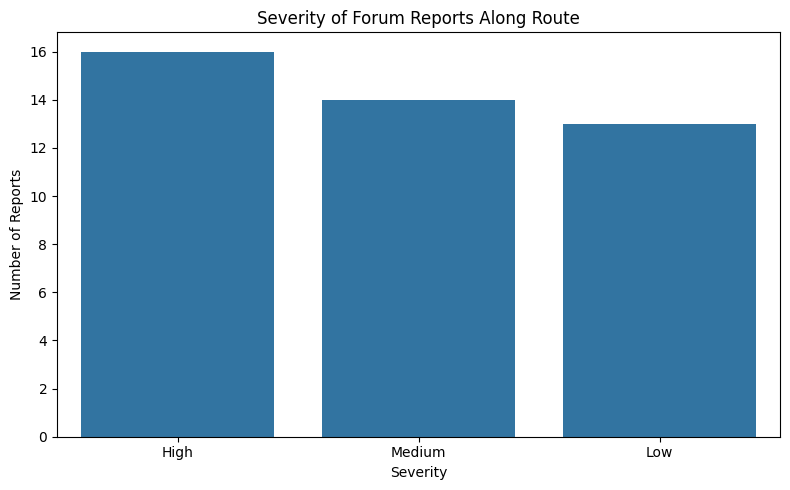

In [ ]:
if not severity_summary.empty:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=severity_summary,
        x="Severity",
        y="Number_of_Reports"
    )

    plt.title("Severity of Forum Reports Along Route")
    plt.xlabel("Severity")
    plt.ylabel("Number of Reports")

    plt.tight_layout()

    plt.savefig(
        REPORT_PATH + "/route_forum_severity.png",
        dpi=300
    )

    plt.show()

In [ ]:
final_report = {
    "source": SOURCE_LOCATION,
    "destination": DESTINATION_LOCATION,

    "source_coordinates": source,
    "destination_coordinates": destination,

    "route_distance_km": round(route_distance, 2),

    "osrm_duration_minutes": round(
        osrm_duration, 2
    ),

    "predicted_delivery_time_minutes": round(
        float(predicted_delivery_time), 2
    ),

    "nearby_forum_reports": len(nearby_posts),

    "nearby_forum_comments": len(nearby_comments),

    "route_summary": route_summary,

    "category_distribution": category_summary.to_dict(
        orient="records"
    ),

    "severity_distribution": severity_summary.to_dict(
        orient="records"
    ),

    "sentiment_distribution": sentiment_summary.to_dict(
        orient="records"
    )
}

with open(
    OUTPUT_PATH + "/final_route_intelligence_report.json",
    "w"
) as f:

    json.dump(
        final_report,
        f,
        indent=4,
        default=str
    )

print("Final route intelligence report generated!")

Final route intelligence report generated!


In [ ]:
print("=" * 55)
print("       SMART RIDE INTELLIGENCE")
print("=" * 55)

print("\nSOURCE:", SOURCE_LOCATION)

print("DESTINATION:", DESTINATION_LOCATION)

print("\nROUTE DISTANCE:", round(route_distance, 2), "km")

print(
    "OSRM DRIVING DURATION:",
    round(osrm_duration, 2),
    "minutes"
)

print(
    "PREDICTED DELIVERY TIME:",
    round(float(predicted_delivery_time), 2),
    "minutes"
)

print(
    "NEARBY FORUM REPORTS:",
    len(nearby_posts)
)

print("\nROUTE INTELLIGENCE SUMMARY:")

print(route_summary)

print("\n" + "=" * 55)

       SMART RIDE INTELLIGENCE

SOURCE: KIIT University
DESTINATION: Bhubaneswar Railway Station

ROUTE DISTANCE: 11.98 km
OSRM DRIVING DURATION: 12.97 minutes
PREDICTED DELIVERY TIME: 23.59 minutes
NEARBY FORUM REPORTS: 43

ROUTE INTELLIGENCE SUMMARY:
43 forum report(s) were found within 500 metres of the selected route. Most common report categories: Traffic (8), Accident (8), Normal (6), Safety Concern (6). Reported severity distribution: High (16), Medium (14), Low (13).

